# Lab 1C: Time and Frequency Domain Representations

Visualize audio signals in time and frequency domains.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display
from scipy import signal
import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully")

Libraries imported successfully


## 1. Load Audio

In [2]:
audio_path = "/home/seetha/PythonScriptsCourses/PythonScriptsCourses/Audio Analysis/Data/XC710407-Warbler.mp3"  # CHANGE THIS

y, sr = librosa.load(audio_path, sr=None)
duration = len(y) / sr
time = np.linspace(0, duration, len(y))

print(f"Sample rate: {sr} Hz")
print(f"Duration: {duration:.2f} seconds")
print(f"Samples: {len(y):,}")

Sample rate: 44100 Hz
Duration: 4.76 seconds
Samples: 209,761


## 2. Time Domain Representations

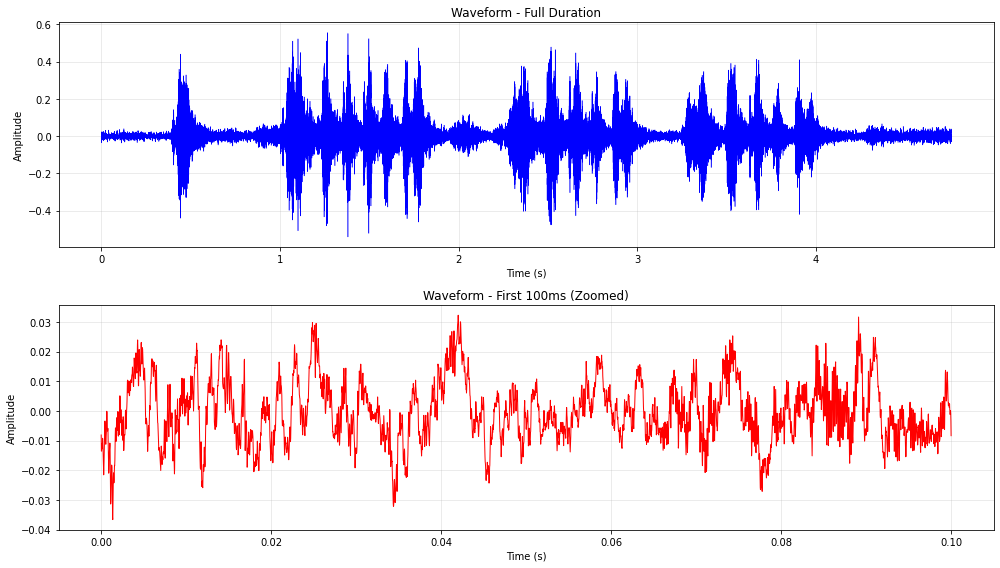

Saved: time_domain_waveform.png


In [3]:
# Waveform representation
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Full waveform
axes[0].plot(time, y, linewidth=0.5, color='blue')
axes[0].set_xlabel('Time (s)')
axes[0].set_ylabel('Amplitude')
axes[0].set_title('Waveform - Full Duration')
axes[0].grid(True, alpha=0.3)

# Zoomed waveform (first 0.1 seconds)
zoom_duration = min(0.1, duration)
zoom_samples = int(zoom_duration * sr)
axes[1].plot(time[:zoom_samples], y[:zoom_samples], linewidth=1, color='red')
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('Amplitude')
axes[1].set_title(f'Waveform - First {zoom_duration*1000:.0f}ms (Zoomed)')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('results/time_domain_waveform.png', dpi=150, bbox_inches='tight')
plt.show()

print("Saved: time_domain_waveform.png")

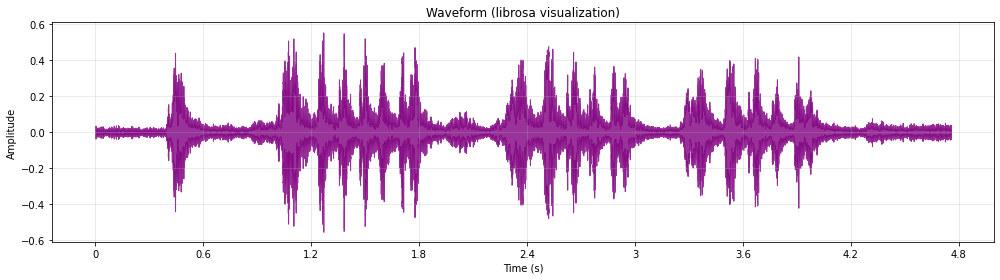

Saved: time_domain_waveshow.png


In [4]:
# Alternative waveform using librosa
plt.figure(figsize=(14, 4))
librosa.display.waveshow(y, sr=sr, alpha=0.8, color='purple')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.title('Waveform (librosa visualization)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('results/time_domain_waveshow.png', dpi=150, bbox_inches='tight')
plt.show()

print("Saved: time_domain_waveshow.png")

## 3. Frequency Domain Representations

### 3.1 FFT Spectrum

In [5]:
# Compute FFT
fft = np.fft.rfft(y)
magnitude = np.abs(fft)
frequencies = np.fft.rfftfreq(len(y), 1/sr)

# Normalize
magnitude = magnitude / len(y)
magnitude[1:-1] *= 2

# Convert to dB
magnitude_db = 20 * np.log10(magnitude + 1e-10)

print(f"Frequency resolution: {frequencies[1] - frequencies[0]:.2f} Hz")
print(f"Max frequency: {frequencies[-1]:.0f} Hz")

Frequency resolution: 0.21 Hz
Max frequency: 22050 Hz


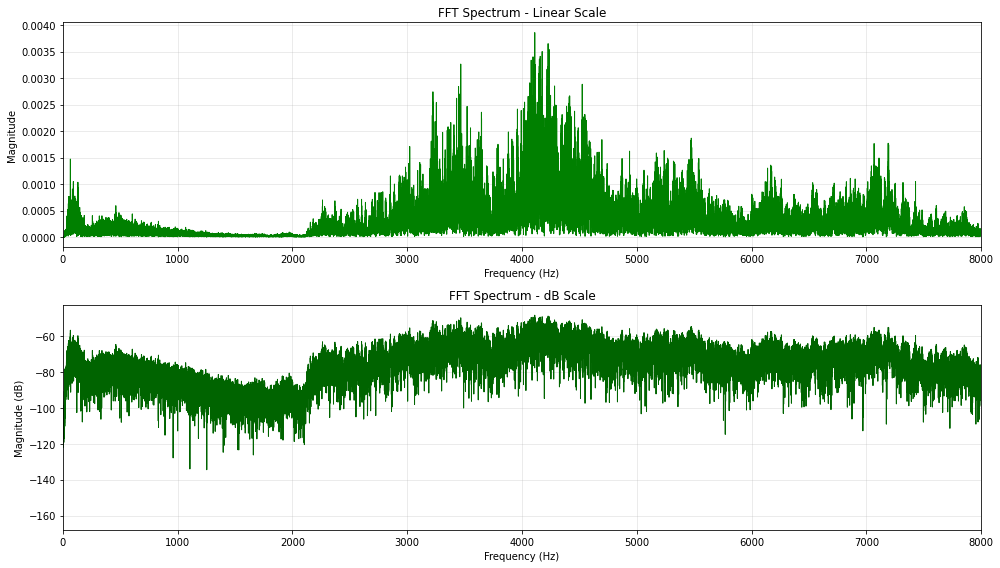

Saved: frequency_domain_fft.png


In [6]:
# Plot FFT spectrum
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Linear scale
axes[0].plot(frequencies, magnitude, linewidth=1, color='green')
axes[0].set_xlabel('Frequency (Hz)')
axes[0].set_ylabel('Magnitude')
axes[0].set_title('FFT Spectrum - Linear Scale')
axes[0].set_xlim(0, min(8000, sr/2))
axes[0].grid(True, alpha=0.3)

# dB scale
axes[1].plot(frequencies, magnitude_db, linewidth=1, color='darkgreen')
axes[1].set_xlabel('Frequency (Hz)')
axes[1].set_ylabel('Magnitude (dB)')
axes[1].set_title('FFT Spectrum - dB Scale')
axes[1].set_xlim(0, min(8000, sr/2))
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('results/frequency_domain_fft.png', dpi=150, bbox_inches='tight')
plt.show()

print("Saved: frequency_domain_fft.png")

### 3.2 Power Spectrum

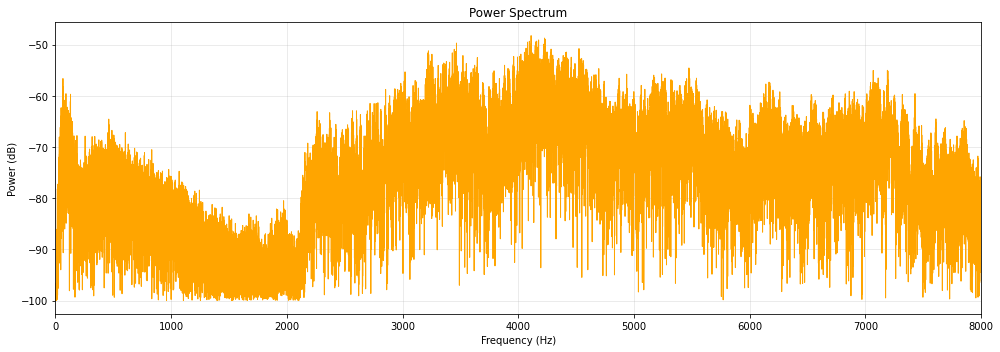

Saved: frequency_domain_power.png


In [7]:
# Compute power spectrum
power = magnitude ** 2
power_db = 10 * np.log10(power + 1e-10)

# Plot power spectrum
plt.figure(figsize=(14, 5))
plt.plot(frequencies, power_db, linewidth=1, color='orange')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power (dB)')
plt.title('Power Spectrum')
plt.xlim(0, min(8000, sr/2))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('results/frequency_domain_power.png', dpi=150, bbox_inches='tight')
plt.show()

print("Saved: frequency_domain_power.png")

### 3.3 Spectrogram (STFT)

In [8]:
# Compute spectrogram using STFT
n_fft = 2048
hop_length = 512

D = librosa.stft(y, n_fft=n_fft, hop_length=hop_length)
magnitude_spec = np.abs(D)
db_spec = librosa.amplitude_to_db(magnitude_spec, ref=np.max)

print(f"Spectrogram shape: {db_spec.shape}")
print(f"Frequency bins: {db_spec.shape[0]}")
print(f"Time frames: {db_spec.shape[1]}")

Spectrogram shape: (1025, 410)
Frequency bins: 1025
Time frames: 410


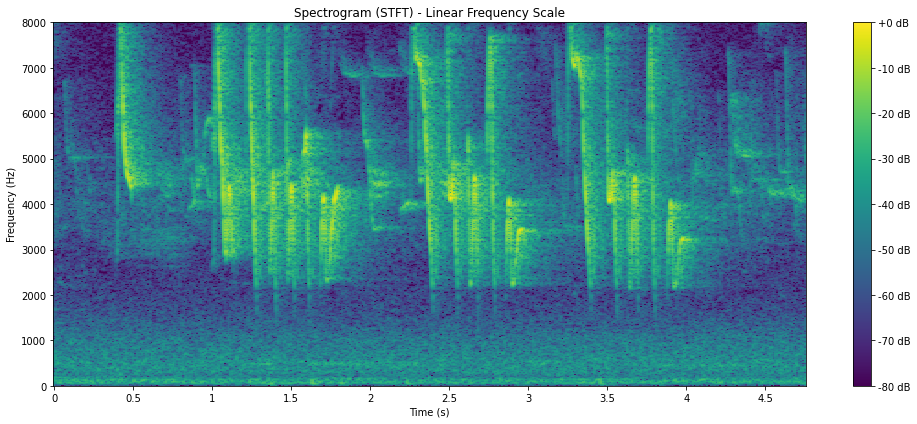

Saved: frequency_domain_spectrogram.png


In [9]:
# Plot spectrogram
plt.figure(figsize=(14, 6))
librosa.display.specshow(db_spec, x_axis='time', y_axis='hz', sr=sr, 
                         hop_length=hop_length, cmap='viridis')
plt.colorbar(format='%+2.0f dB')
plt.xlabel('Time (s)')
plt.ylabel('Frequency (Hz)')
plt.title('Spectrogram (STFT) - Linear Frequency Scale')
plt.ylim(0, 8000)
plt.tight_layout()
plt.savefig('results/frequency_domain_spectrogram.png', dpi=150, bbox_inches='tight')
plt.show()

print("Saved: frequency_domain_spectrogram.png")

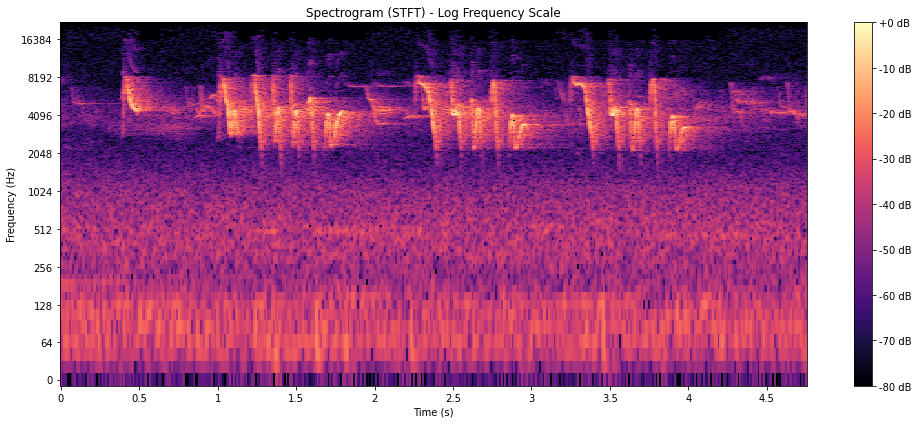

Saved: frequency_domain_spectrogram_log.png


In [10]:
# Plot spectrogram - log frequency scale
plt.figure(figsize=(14, 6))
librosa.display.specshow(db_spec, x_axis='time', y_axis='log', sr=sr,
                         hop_length=hop_length, cmap='magma')
plt.colorbar(format='%+2.0f dB')
plt.xlabel('Time (s)')
plt.ylabel('Frequency (Hz)')
plt.title('Spectrogram (STFT) - Log Frequency Scale')
plt.tight_layout()
plt.savefig('results/frequency_domain_spectrogram_log.png', dpi=150, bbox_inches='tight')
plt.show()

print("Saved: frequency_domain_spectrogram_log.png")

### 3.4 Mel Spectrogram

In [11]:
# Compute mel spectrogram
n_mels = 128

mel_spec = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=n_fft, 
                                          hop_length=hop_length, n_mels=n_mels)
mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)

print(f"Mel spectrogram shape: {mel_spec_db.shape}")
print(f"Mel bins: {mel_spec_db.shape[0]}")
print(f"Time frames: {mel_spec_db.shape[1]}")

Mel spectrogram shape: (128, 410)
Mel bins: 128
Time frames: 410


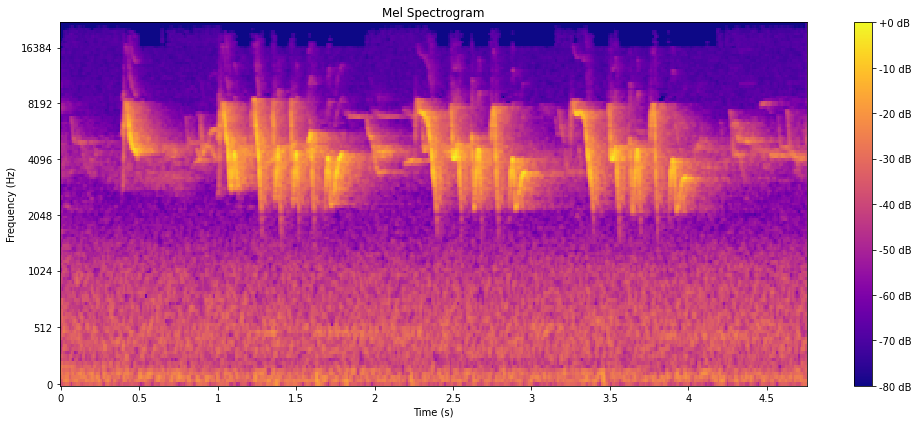

Saved: frequency_domain_mel_spectrogram.png


In [12]:
# Plot mel spectrogram
plt.figure(figsize=(14, 6))
librosa.display.specshow(mel_spec_db, x_axis='time', y_axis='mel', sr=sr,
                         hop_length=hop_length, cmap='plasma')
plt.colorbar(format='%+2.0f dB')
plt.xlabel('Time (s)')
plt.ylabel('Frequency (Hz)')
plt.title('Mel Spectrogram')
plt.tight_layout()
plt.savefig('results/frequency_domain_mel_spectrogram.png', dpi=150, bbox_inches='tight')
plt.show()

print("Saved: frequency_domain_mel_spectrogram.png")

## 4. Comprehensive Comparison

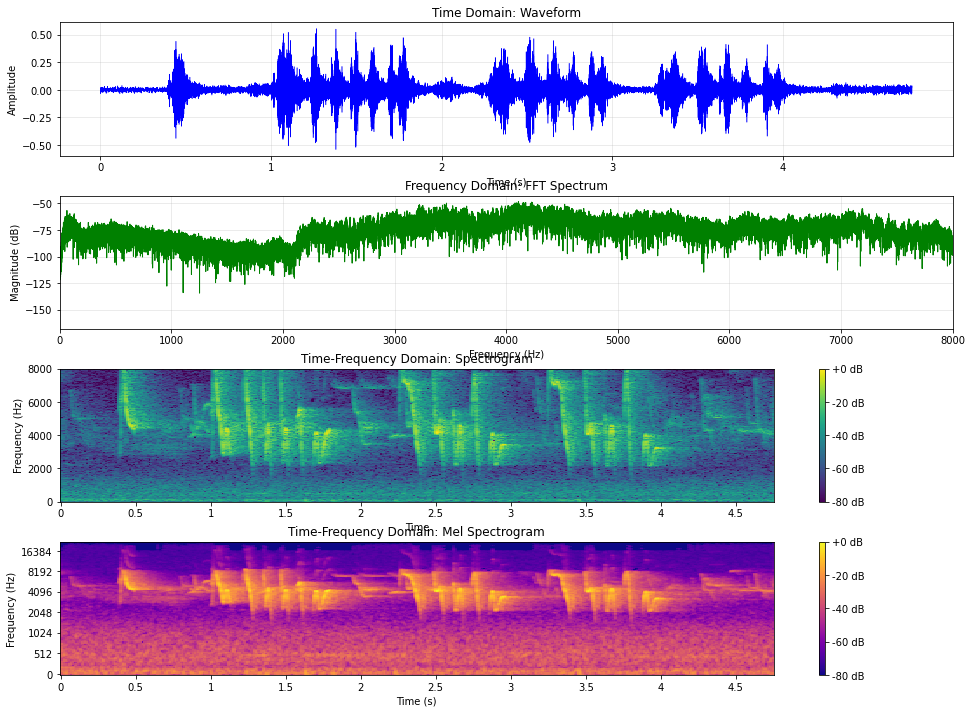

Saved: complete_representation_comparison.png


In [13]:
# Combined visualization
fig = plt.figure(figsize=(16, 12))
gs = fig.add_gridspec(4, 2, hspace=0.3, wspace=0.3)

# Time domain - waveform
ax1 = fig.add_subplot(gs[0, :])
ax1.plot(time, y, linewidth=0.5, color='blue')
ax1.set_xlabel('Time (s)')
ax1.set_ylabel('Amplitude')
ax1.set_title('Time Domain: Waveform')
ax1.grid(True, alpha=0.3)

# Frequency domain - FFT
ax2 = fig.add_subplot(gs[1, :])
ax2.plot(frequencies, magnitude_db, linewidth=1, color='green')
ax2.set_xlabel('Frequency (Hz)')
ax2.set_ylabel('Magnitude (dB)')
ax2.set_title('Frequency Domain: FFT Spectrum')
ax2.set_xlim(0, min(8000, sr/2))
ax2.grid(True, alpha=0.3)

# Time-Frequency - Spectrogram
ax3 = fig.add_subplot(gs[2, :])
img1 = librosa.display.specshow(db_spec, x_axis='time', y_axis='hz', sr=sr,
                                hop_length=hop_length, ax=ax3, cmap='viridis')
ax3.set_ylabel('Frequency (Hz)')
ax3.set_title('Time-Frequency Domain: Spectrogram')
ax3.set_ylim(0, 8000)
plt.colorbar(img1, ax=ax3, format='%+2.0f dB')

# Time-Frequency - Mel Spectrogram
ax4 = fig.add_subplot(gs[3, :])
img2 = librosa.display.specshow(mel_spec_db, x_axis='time', y_axis='mel', sr=sr,
                                hop_length=hop_length, ax=ax4, cmap='plasma')
ax4.set_xlabel('Time (s)')
ax4.set_ylabel('Frequency (Hz)')
ax4.set_title('Time-Frequency Domain: Mel Spectrogram')
plt.colorbar(img2, ax=ax4, format='%+2.0f dB')

plt.savefig('results/complete_representation_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print("Saved: complete_representation_comparison.png")

## 5. Phase Information

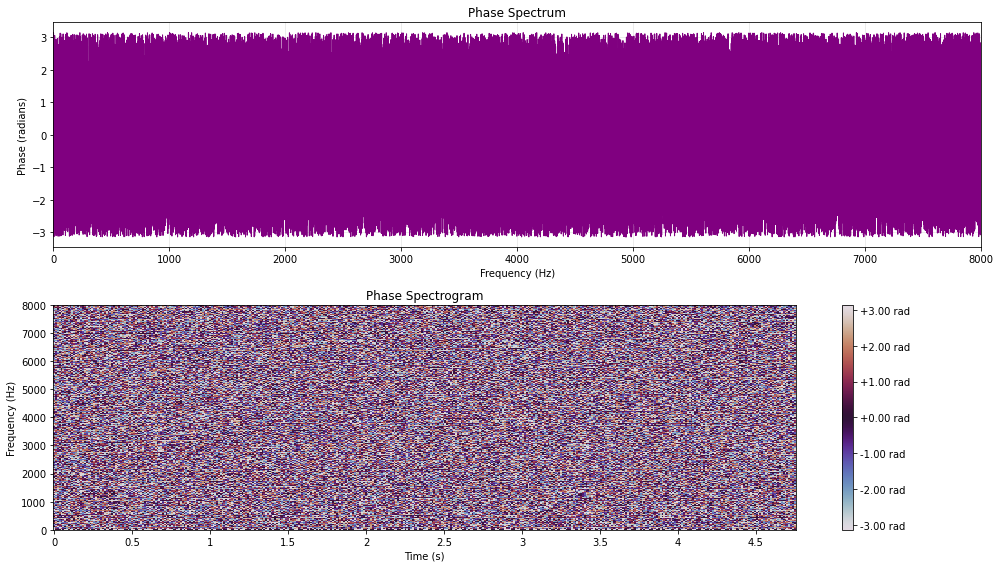

Saved: phase_representations.png


In [14]:
# Phase spectrum from FFT
phase = np.angle(fft)

# Phase spectrogram from STFT
phase_spec = np.angle(D)

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Phase spectrum
axes[0].plot(frequencies, phase, linewidth=1, color='purple')
axes[0].set_xlabel('Frequency (Hz)')
axes[0].set_ylabel('Phase (radians)')
axes[0].set_title('Phase Spectrum')
axes[0].set_xlim(0, min(8000, sr/2))
axes[0].grid(True, alpha=0.3)

# Phase spectrogram
img = librosa.display.specshow(phase_spec, x_axis='time', y_axis='hz', sr=sr,
                              hop_length=hop_length, ax=axes[1], cmap='twilight')
axes[1].set_ylabel('Frequency (Hz)')
axes[1].set_xlabel('Time (s)')
axes[1].set_title('Phase Spectrogram')
axes[1].set_ylim(0, 8000)
plt.colorbar(img, ax=axes[1], format='%+2.2f rad')

plt.tight_layout()
plt.savefig('results/phase_representations.png', dpi=150, bbox_inches='tight')
plt.show()

print("Saved: phase_representations.png")

## 6. Spectrogram Parameter Comparison

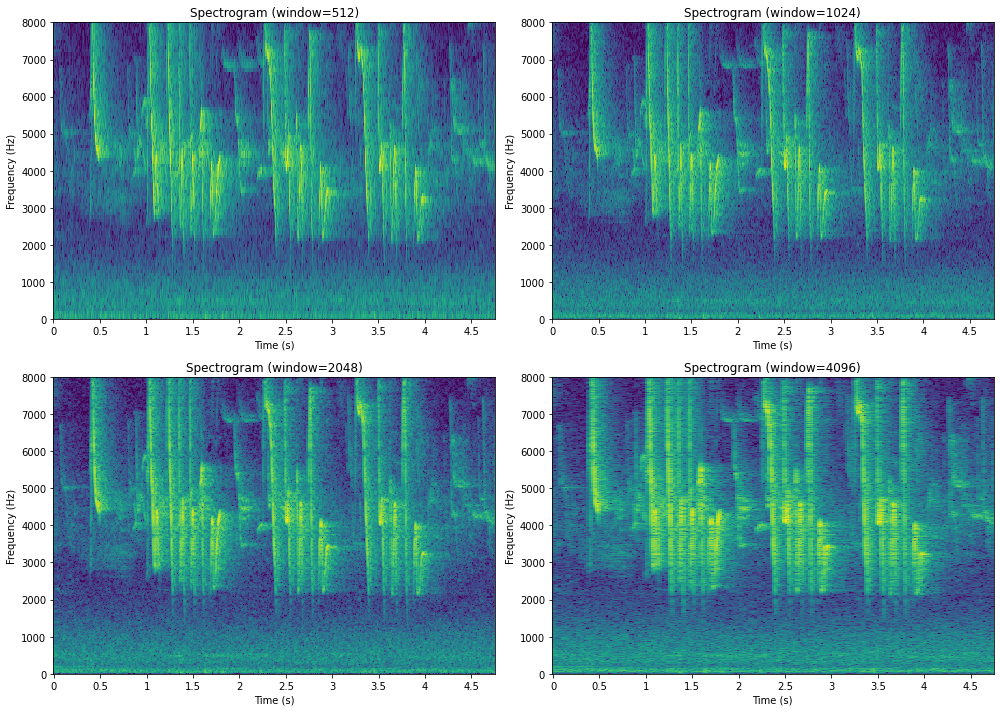

Saved: spectrogram_window_comparison.png


In [15]:
# Compare different window sizes
window_sizes = [512, 1024, 2048, 4096]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for i, n_fft in enumerate(window_sizes):
    D_temp = librosa.stft(y, n_fft=n_fft, hop_length=n_fft//4)
    db_temp = librosa.amplitude_to_db(np.abs(D_temp), ref=np.max)
    
    librosa.display.specshow(db_temp, x_axis='time', y_axis='hz', sr=sr,
                            hop_length=n_fft//4, ax=axes[i], cmap='viridis')
    axes[i].set_ylabel('Frequency (Hz)')
    axes[i].set_xlabel('Time (s)')
    axes[i].set_title(f'Spectrogram (window={n_fft})')
    axes[i].set_ylim(0, 8000)

plt.tight_layout()
plt.savefig('results/spectrogram_window_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print("Saved: spectrogram_window_comparison.png")

## Summary

This notebook demonstrated audio representations:

**Time Domain:**
- Waveform (amplitude vs time)

**Frequency Domain:**
- FFT spectrum (magnitude vs frequency)
- Power spectrum
- Phase spectrum

**Time-Frequency Domain:**
- Spectrogram (STFT)
- Mel spectrogram
- Phase spectrogram

**Output Files:**
- `time_domain_waveform.png`
- `time_domain_waveshow.png`
- `frequency_domain_fft.png`
- `frequency_domain_power.png`
- `frequency_domain_spectrogram.png`
- `frequency_domain_spectrogram_log.png`
- `frequency_domain_mel_spectrogram.png`
- `complete_representation_comparison.png`
- `phase_representations.png`
- `spectrogram_window_comparison.png`